In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_excel("/content/Telco_customer_churn.xlsx")

In [ ]:
print(df.head())

   CustomerID  Count        Country       State         City  Zip Code  \
0  3668-QPYBK      1  United States  California  Los Angeles     90003   
1  9237-HQITU      1  United States  California  Los Angeles     90005   
2  9305-CDSKC      1  United States  California  Los Angeles     90006   
3  7892-POOKP      1  United States  California  Los Angeles     90010   
4  0280-XJGEX      1  United States  California  Los Angeles     90015   

                 Lat Long   Latitude   Longitude  Gender  ...        Contract  \
0  33.964131, -118.272783  33.964131 -118.272783    Male  ...  Month-to-month   
1   34.059281, -118.30742  34.059281 -118.307420  Female  ...  Month-to-month   
2  34.048013, -118.293953  34.048013 -118.293953  Female  ...  Month-to-month   
3  34.062125, -118.315709  34.062125 -118.315709  Female  ...  Month-to-month   
4  34.039224, -118.266293  34.039224 -118.266293    Male  ...  Month-to-month   

  Paperless Billing             Payment Method  Monthly Charges Tota

In [ ]:
print(df.shape)

(7043, 33)


In [ ]:
print(df.columns)

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [ ]:
print(df.describe())

        Count      Zip Code     Latitude    Longitude  Tenure Months  \
count  7043.0   7043.000000  7043.000000  7043.000000    7043.000000   
mean      1.0  93521.964646    36.282441  -119.798880      32.371149   
std       0.0   1865.794555     2.455723     2.157889      24.559481   
min       1.0  90001.000000    32.555828  -124.301372       0.000000   
25%       1.0  92102.000000    34.030915  -121.815412       9.000000   
50%       1.0  93552.000000    36.391777  -119.730885      29.000000   
75%       1.0  95351.000000    38.224869  -118.043237      55.000000   
max       1.0  96161.000000    41.962127  -114.192901      72.000000   

       Monthly Charges  Churn Value  Churn Score         CLTV  
count      7043.000000  7043.000000  7043.000000  7043.000000  
mean         64.761692     0.265370    58.699418  4400.295755  
std          30.090047     0.441561    21.525131  1183.057152  
min          18.250000     0.000000     5.000000  2003.000000  
25%          35.500000     0.00

In [ ]:
df.isnull().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
CustomerID,0.000000
Count,0.000000
Country,0.000000
State,0.000000
City,0.000000
Zip Code,0.000000
Lat Long,0.000000
Latitude,0.000000
Longitude,0.000000
Gender,0.000000


In [ ]:
print(df.duplicated().sum())

0


In [ ]:
df["Churn Reason"] = df["Churn Reason"].fillna("Not Applicable")

In [ ]:
df.isnull().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


In [ ]:
print(df.dtypes)

CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn Label           object
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason          object
dtype: object


In [ ]:
df["Churn"] = df["Churn Label"].map({
    "Yes": 1,
    "No": 0
})

In [ ]:
df["Churn"].value_counts()

,count
Churn,
0,5174
1,1869


In [ ]:
df = df.drop("CustomerID", axis=1)

In [ ]:
print(df.head())

   Count        Country       State         City  Zip Code  \
0      1  United States  California  Los Angeles     90003   
1      1  United States  California  Los Angeles     90005   
2      1  United States  California  Los Angeles     90006   
3      1  United States  California  Los Angeles     90010   
4      1  United States  California  Los Angeles     90015   

                 Lat Long   Latitude   Longitude  Gender Senior Citizen  ...  \
0  33.964131, -118.272783  33.964131 -118.272783    Male             No  ...   
1   34.059281, -118.30742  34.059281 -118.307420  Female             No  ...   
2  34.048013, -118.293953  34.048013 -118.293953  Female             No  ...   
3  34.062125, -118.315709  34.062125 -118.315709  Female             No  ...   
4  34.039224, -118.266293  34.039224 -118.266293    Male             No  ...   

  Paperless Billing             Payment Method  Monthly Charges Total Charges  \
0               Yes               Mailed check            53.85  

In [ ]:
print(df.tail())

      Count        Country       State          City  Zip Code  \
7038      1  United States  California       Landers     92285   
7039      1  United States  California      Adelanto     92301   
7040      1  United States  California         Amboy     92304   
7041      1  United States  California  Angelus Oaks     92305   
7042      1  United States  California  Apple Valley     92308   

                    Lat Long   Latitude   Longitude  Gender Senior Citizen  \
7038  34.341737, -116.539416  34.341737 -116.539416  Female             No   
7039  34.667815, -117.536183  34.667815 -117.536183    Male             No   
7040  34.559882, -115.637164  34.559882 -115.637164  Female             No   
7041     34.1678, -116.86433  34.167800 -116.864330  Female             No   
7042  34.424926, -117.184503  34.424926 -117.184503    Male             No   

      ... Paperless Billing             Payment Method  Monthly Charges  \
7038  ...               Yes  Bank transfer (automatic)     

In [ ]:
print(df["Churn Label"].value_counts())

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64


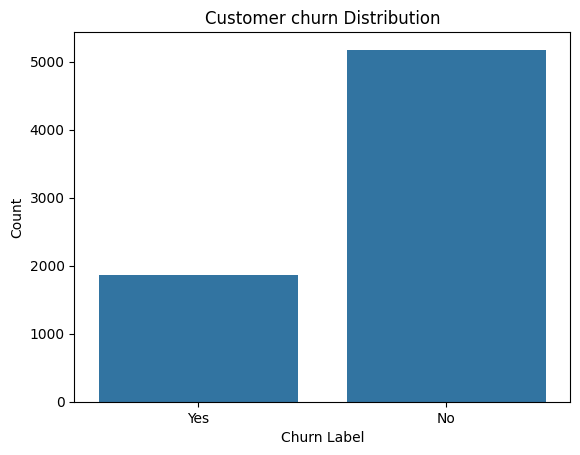

In [ ]:
sns.countplot(data = df, x = "Churn Label")
plt.title("Customer churn Distribution")
plt.xlabel("Churn Label")
plt.ylabel("Count")
plt.show()

In [ ]:
churn_rate = (df["Churn"].sum() / len(df)) * 100
print("Churn Rate:", round(churn_rate, 2), "%")

Churn Rate: 26.54 %


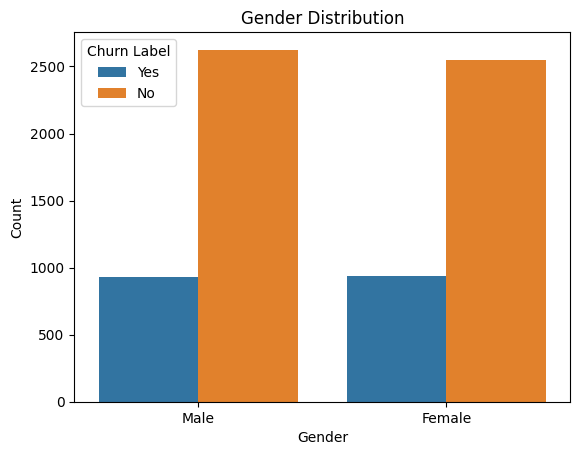

In [ ]:
sns.countplot(data = df, x = "Gender", hue = "Churn Label")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

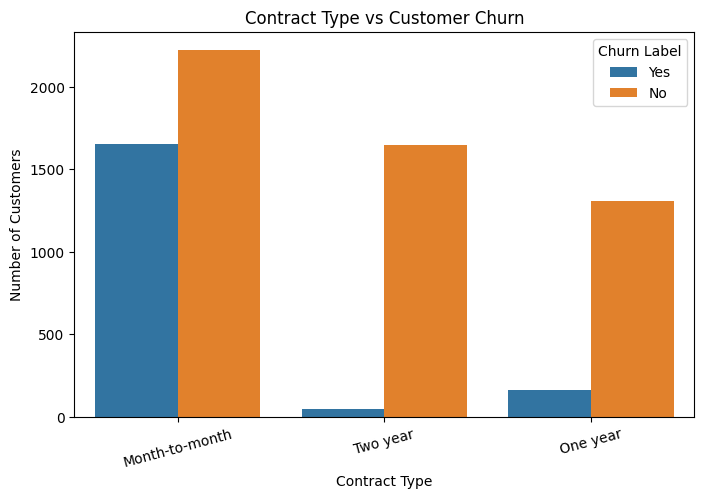

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data = df, x = "Contract", hue = "Churn Label")
plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.show()

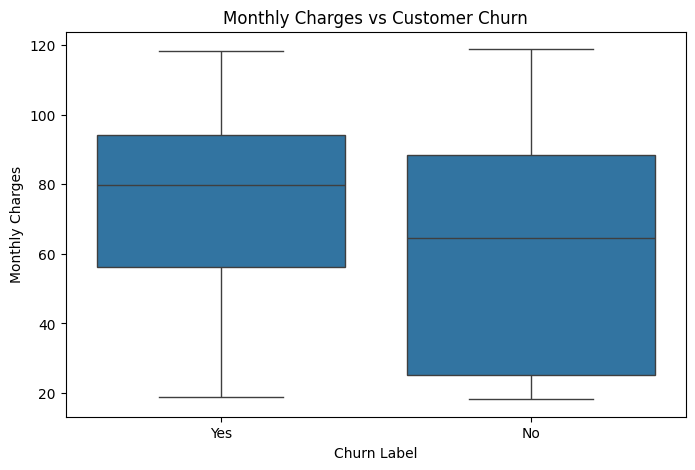

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data = df, x = "Churn Label", y = "Monthly Charges")
plt.title("Monthly Charges vs Customer Churn")
plt.show()

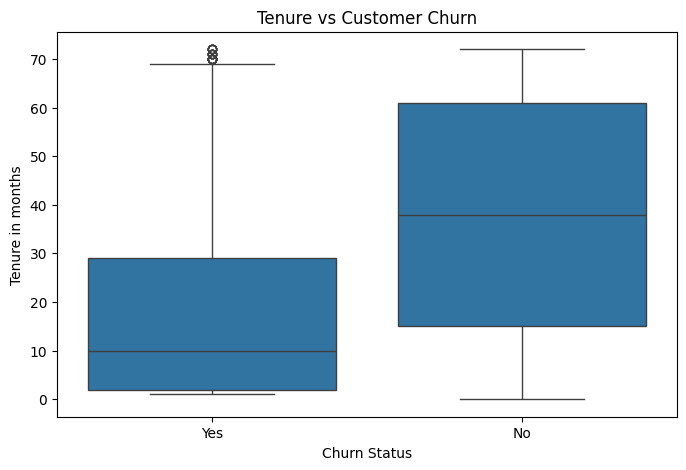

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data = df, x = "Churn Label", y = "Tenure Months")
plt.title("Tenure vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure in months")
plt.show()

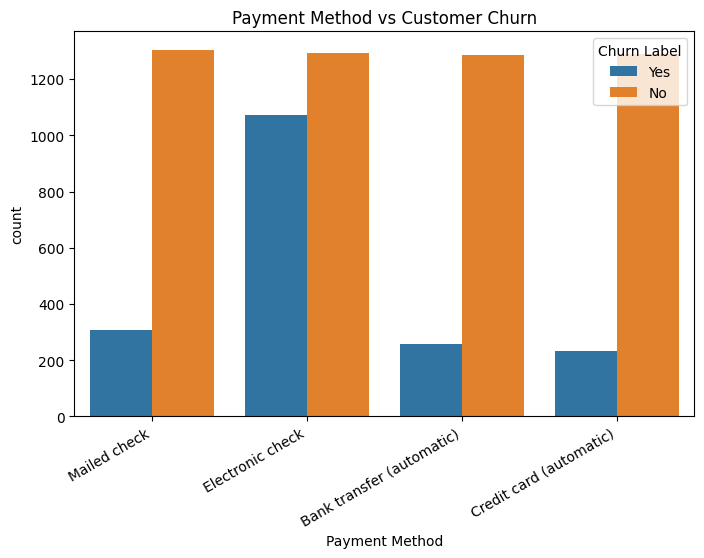

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data = df, x = "Payment Method", hue = "Churn Label")
plt.title("Payment Method vs Customer Churn")
plt.xticks(rotation=30, ha='right')
plt.show()

In [ ]:
import pandas as pd

# Ensure the dataframe is loaded if the session was reset
try:
    df_model = df.copy()
except NameError:
    df = pd.read_excel("/content/Telco_customer_churn.xlsx")
    df_model = df.copy()

# Corrected 'Customer ID' to 'CustomerID' to match the dataset's actual column name
drop_columns = [
    "CustomerID",
    "Country",
    "State",
    "City",
    "Lat Long",
    "Zip Code",
    "Latitude",
    "Longitude",
    "Churn Label",
    "Churn Score",
    "Churn Reason",
    "CLTV"
]

df_model = df_model.drop(columns=drop_columns, errors='ignore')

print(df_model.head())
print(df_model.shape)

   Count  Gender Senior Citizen Partner Dependents  Tenure Months  \
0      1    Male             No      No         No              2   
1      1  Female             No      No        Yes              2   
2      1  Female             No      No        Yes              8   
3      1  Female             No     Yes        Yes             28   
4      1    Male             No      No        Yes             49   

  Phone Service Multiple Lines Internet Service Online Security  ...  \
0           Yes             No              DSL             Yes  ...   
1           Yes             No      Fiber optic              No  ...   
2           Yes            Yes      Fiber optic              No  ...   
3           Yes            Yes      Fiber optic              No  ...   
4           Yes            Yes      Fiber optic              No  ...   

  Device Protection Tech Support Streaming TV Streaming Movies  \
0                No           No           No               No   
1                No 

In [ ]:
x = df_model.drop("Churn Value", axis=1)
y = df_model["Churn Value"]

print("Features:", x.shape)
print("Target:", y.shape)


Features: (7043, 20)
Target: (7043,)


In [ ]:
categorical_columns = x.select_dtypes(include=['object']).columns
numerical_columns = x.select_dtypes(include=['int64', 'float64']).columns

print("Categorical Columns:", categorical_columns)
print("\nNumerical Columns:", numerical_columns)

Categorical Columns: Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Total Charges'],
      dtype='object')

Numerical Columns: Index(['Count', 'Tenure Months', 'Monthly Charges'], dtype='object')


In [ ]:
x_encoded = pd.get_dummies(x, columns=categorical_columns, drop_first=True)
print(x_encoded.head())
print(x_encoded.shape)

   Count  Tenure Months  Monthly Charges  Gender_Male  Senior Citizen_Yes  \
0      1              2            53.85         True               False   
1      1              2            70.70        False               False   
2      1              8            99.65        False               False   
3      1             28           104.80        False               False   
4      1             49           103.70         True               False   

   Partner_Yes  Dependents_Yes  Phone Service_Yes  \
0        False           False               True   
1        False            True               True   
2        False            True               True   
3         True            True               True   
4        False            True               True   

   Multiple Lines_No phone service  Multiple Lines_Yes  ...  \
0                            False               False  ...   
1                            False               False  ...   
2                            

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42, stratify=y)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)


Training Data: (5634, 6560)
Testing Data: (1409, 6560)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print(x_train_scaled.shape)
print(x_test_scaled.shape)

(5634, 6560)
(1409, 6560)


In [ ]:
print("Training Features:", x_train_scaled.shape)
print("Testing Features:", x_test_scaled.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nMissing Values:", df_model.isnull().sum().sum())

Training Features: (5634, 6560)
Testing Features: (1409, 6560)
Training Target: (5634,)
Testing Target: (1409,)

Missing Values: 0


In [ ]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression Imported Successfully!")

Logistic Regression Imported Successfully!


In [ ]:
model = LogisticRegression(max_iter=1000)
print(model)

LogisticRegression(max_iter=1000)


In [ ]:
model.fit(x_train_scaled, y_train)
print("Model Trained Successfully!")


Model Trained Successfully!


In [ ]:
y_pred = model.predict(x_test_scaled)
print(y_pred)

[0 1 0 ... 0 0 0]


In [ ]:
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
print(comparison.head(10))

   Actual  Predicted
0       0          0
1       0          1
2       0          0
3       0          0
4       0          0
5       0          1
6       0          1
7       0          0
8       0          0
9       1          1


In [ ]:
probabilities = model.predict_proba(x_test_scaled)
print(probabilities[:5])

[[9.95554574e-01 4.44542648e-03]
 [2.68482035e-01 7.31517965e-01]
 [9.99803439e-01 1.96561331e-04]
 [7.74248855e-01 2.25751145e-01]
 [9.98285917e-01 1.71408316e-03]]


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Confusion Matrix:\n", conf_matrix)

Accuracy: 0.772888573456352
Precision: 0.5865384615384616
Recall: 0.4893048128342246
F1 Score: 0.5335276967930029
Confusion Matrix:
 [[906 129]
 [191 183]]


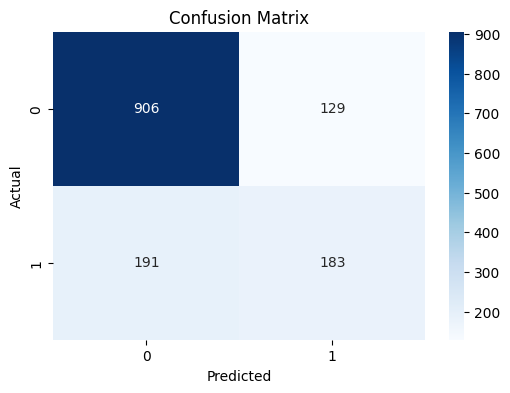

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1035
           1       0.59      0.49      0.53       374

    accuracy                           0.77      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.76      0.77      0.77      1409



In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("\nConfusion Matrix:\n", conf_matrix)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.772888573456352
Precision: 0.5865384615384616
Recall: 0.4893048128342246
F1 Score: 0.5335276967930029

Confusion Matrix:
 [[906 129]
 [191 183]]

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.88      0.85      1035
           1       0.59      0.49      0.53       374

    accuracy                           0.77      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.76      0.77      0.77      1409



In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Safely regenerate training variables if they were cleared from memory
try:
    _ = x_train_scaled
    _ = y_train
except NameError:
    # 1. Load data
    df = pd.read_excel("/content/Telco_customer_churn.xlsx")

    # 2. Clean 'Total Charges' (convert to numeric, replace blank spaces with NaN/0)
    df["Total Charges"] = pd.to_numeric(df["Total Charges"].astype(str).str.strip(), errors='coerce')
    df["Total Charges"] = df["Total Charges"].fillna(0)

    # 3. Handle 'Churn Reason' missing values
    df["Churn Reason"] = df["Churn Reason"].fillna("Not Applicable")

    # 4. Drop non-predictive metadata columns
    drop_columns = [
        "CustomerID", "Country", "State", "City", "Lat Long", "Zip Code",
        "Latitude", "Longitude", "Churn Label", "Churn Score", "Churn Reason", "CLTV"
    ]
    df_model = df.drop(columns=drop_columns, errors='ignore')

    # 5. Separate features and target
    x = df_model.drop("Churn Value", axis=1)
    y = df_model["Churn Value"]

    # 6. One-hot encode categorical features
    categorical_columns = x.select_dtypes(include=['object']).columns
    x_encoded = pd.get_dummies(x, columns=categorical_columns, drop_first=True)

    # 7. Split and scale data
    x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42, stratify=y)
    scaler = StandardScaler()
    x_train_scaled = scaler.fit_transform(x_train)
    x_test_scaled = scaler.transform(x_test)

# Train Decision Tree Model
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(x_train_scaled, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [ ]:
df_pred = dt_model.predict(x_test_scaled)
print(df_pred[:10])

[0 1 0 1 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, df_pred)
print(classification_report(y_test, df_pred))
print("Accuracy:", accuracy)

              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1035
           1       0.59      0.63      0.61       374

    accuracy                           0.79      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.79      0.79      1409

Accuracy: 0.7877927608232789


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, max_depth=100, random_state=42)
rf_model.fit(x_train_scaled, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [ ]:
rf_pred = rf_model.predict(x_test_scaled)
print(rf_pred[:10])

[0 1 0 0 0 0 0 0 0 0]


In [ ]:
rf_accurancy = accuracy_score(y_test, rf_pred)
print("Random forest Accuracy:", rf_accurancy)

Random forest Accuracy: 0.7920511000709723


In [ ]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression

# Safely regenerate y_pred if it was cleared from memory
try:
    _ = y_pred
except NameError:
    lr_model = LogisticRegression(max_iter=1000)
    lr_model.fit(x_train_scaled, y_train)
    y_pred = lr_model.predict(x_test_scaled)

# Calculate accuracy for Logistic Regression
lr_accuracy = accuracy_score(y_test, y_pred)

# Build and print results DataFrame
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [lr_accuracy, accuracy, rf_accurancy]
})

print(results)

                 Model  Accuracy
0  Logistic Regression  0.799858
1        Decision Tree  0.787793
2        Random Forest  0.792051


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

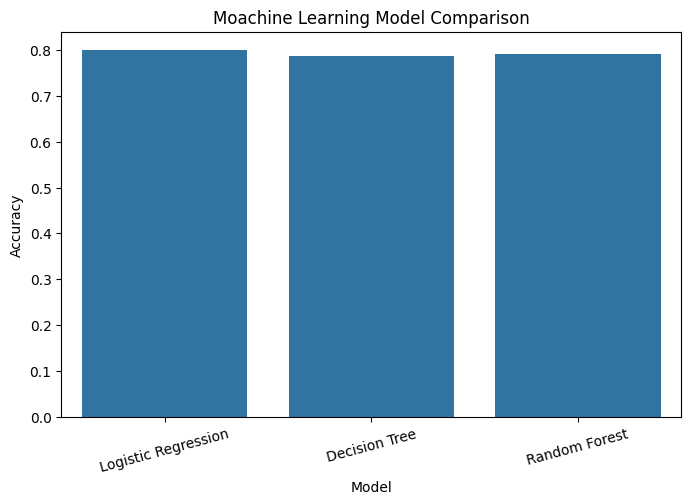

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(data=results, x="Model", y="Accuracy")
plt.title("Moachine Learning Model Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.show()

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

print(feature_importance.head(10))

                            Feature  Importance
3                     Total Charges    0.195444
1                     Tenure Months    0.162199
2                   Monthly Charges    0.161806
11     Internet Service_Fiber optic    0.042424
7                    Dependents_Yes    0.038891
29  Payment Method_Electronic check    0.038520
26                Contract_Two year    0.032268
4                       Gender_Male    0.028206
27            Paperless Billing_Yes    0.026046
6                       Partner_Yes    0.024416


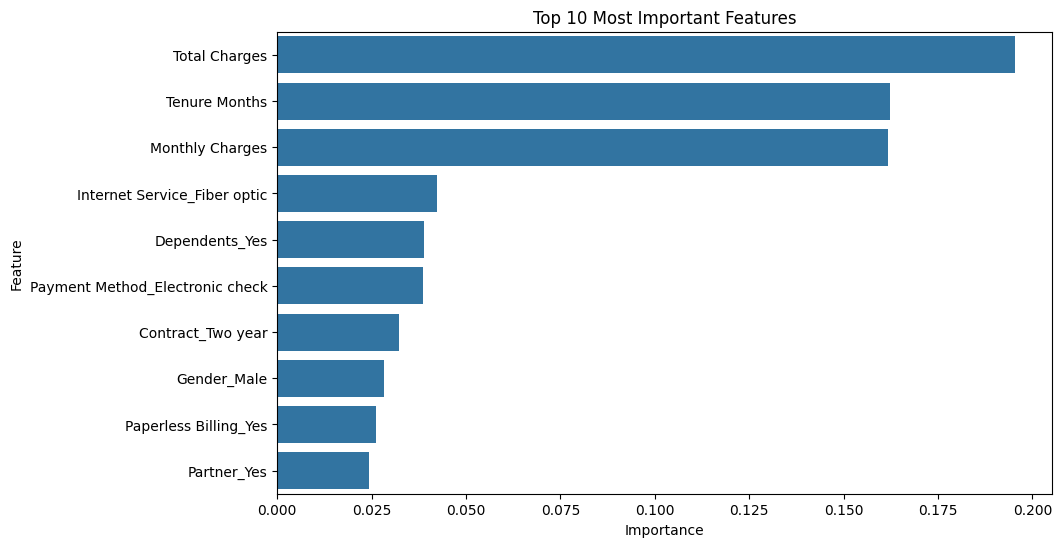

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(data=feature_importance.head(10), x="Importance", y="Feature")
plt.title("Top 10 Most Important Features")
plt.show()

In [ ]:
df.to_excel("/content/Telco_customer_churn.xlsx", index=False)

In [ ]:
from google.colab import files

files.download("/content/Telco_customer_churn.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# Safely regenerate training variables if they were cleared from memory
try:
    _ = x_train_scaled
    _ = y_train
except NameError:
    # 1. Load data
    df = pd.read_excel("/content/Telco_customer_churn.xlsx")

    # 2. Clean 'Total Charges' (convert to numeric, replace blank spaces with NaN/0)
    df["Total Charges"] = pd.to_numeric(df["Total Charges"].astype(str).str.strip(), errors='coerce')
    df["Total Charges"] = df["Total Charges"].fillna(0)

    # 3. Handle 'Churn Reason' missing values
    df["Churn Reason"] = df["Churn Reason"].fillna("Not Applicable")

    # 4. Drop non-predictive metadata columns
    drop_columns = [
        "CustomerID", "Country", "State", "City", "Lat Long", "Zip Code",
        "Latitude", "Longitude", "Churn Label", "Churn Score", "Churn Reason", "CLTV"
    ]
    df_model = df.drop(columns=drop_columns, errors='ignore')

    # 5. Separate features and target
    x = df_model.drop("Churn Value", axis=1)
    y = df_model["Churn Value"]

    # 6. One-hot encode categorical features
    categorical_columns = x.select_dtypes(include=['object']).columns
    x_encoded = pd.get_dummies(x, columns=categorical_columns, drop_first=True)

    # 7. Split and scale data
    x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42, stratify=y)
    scaler = StandardScaler()
    x_train_scaled = scaler.fit_transform(x_train)
    x_test_scaled = scaler.transform(x_test)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_model = RandomForestClassifier(random_state=42, class_weight="balanced")
grid_search = GridSearchCV(estimator=rf_model, param_grid=param_grid, cv=3, n_jobs=-1, verbose=1)
grid_search.fit(x_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-validation Recall:", grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best Cross-validation Recall: 0.8020944266950657


In [6]:
import joblib

# Safely extract the best estimator from the grid search results
try:
    best_model = grid_search.best_estimator_
    joblib.dump(best_model, "customer_churn_model.pkl")
    print("Model saved successfully!")
except NameError:
    print("Error: 'grid_search' is not defined. Please run the GridSearchCV cell (5_VzAQJo71Nl) first.")

Model saved successfully!


In [7]:
from google.colab import files

files.download("/content/customer_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>